<a href="https://colab.research.google.com/github/selmirayen870-wq/titanic_survival_prediction/blob/main/titanic_survival_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
   import pandas as pd
   import numpy as np
   print(pd.__version__, np.__version__)

2.2.3 2.1.3


In [2]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.shape

(891, 12)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [5]:
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [6]:
df.groupby("Sex")["Survived"].mean()

,Survived
Sex,
female,0.742038
male,0.188908


In [7]:
df.groupby("Pclass")["Survived"].mean()

,Survived
Pclass,
1,0.629630
2,0.472826
3,0.242363


In [10]:
# 1. Embarked : remplacer par le mode
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])

In [11]:
# 2. Age : médiane par groupe (sexe + classe)
df["Age"] = df["Age"].fillna(
    df.groupby(["Sex", "Pclass"])["Age"].transform("median")
)

In [12]:
# 3. Cabin : créer une variable indiquant si la cabine est connue, puis supprimer l'originale
df["HasCabin"] = df["Cabin"].notna().astype(int)
df = df.drop(columns=["Cabin"])

In [13]:
# 4. Vérification : tout doit être à 0
df.isna().sum()

,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0


In [14]:
df.groupby("HasCabin")["Survived"].mean()

,Survived
HasCabin,
0,0.299854
1,0.666667


In [15]:
df.groupby(["Pclass", "HasCabin"])["Survived"].agg(["mean", "count"])

mean  count
Pclass HasCabin                 
1      0         0.475000     40
       1         0.664773    176
2      0         0.440476    168
       1         0.812500     16
3      0         0.235908    479
       1         0.500000     12

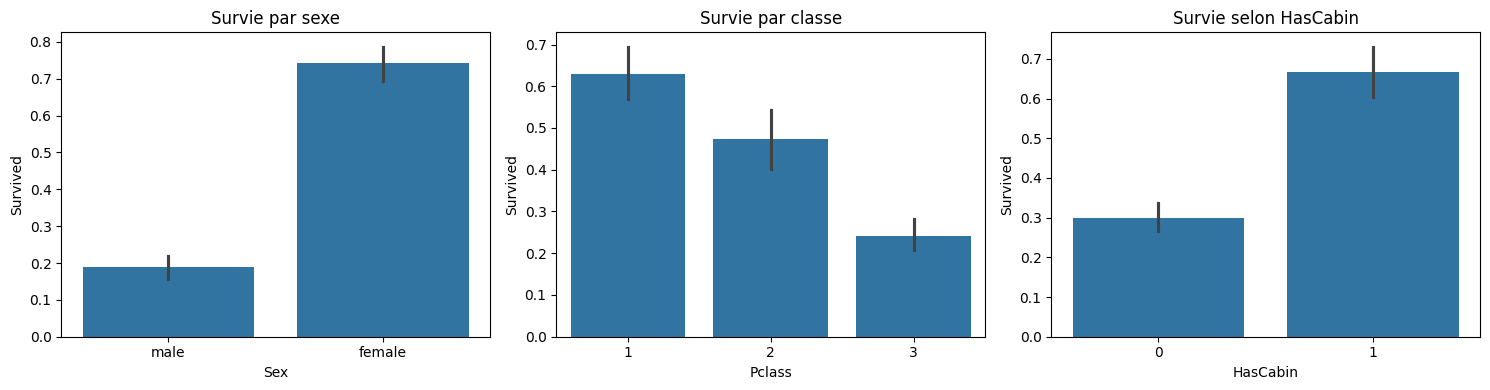

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[0])
axes[0].set_title("Survie par sexe")

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[1])
axes[1].set_title("Survie par classe")

sns.barplot(data=df, x="HasCabin", y="Survived", ax=axes[2])
axes[2].set_title("Survie selon HasCabin")

plt.tight_layout()
plt.show()

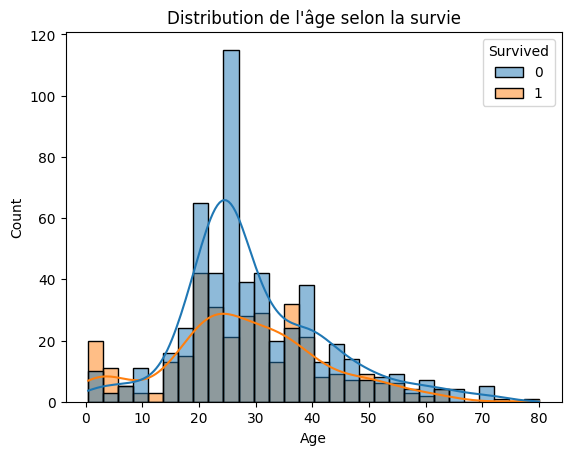

In [17]:
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True)
plt.title("Distribution de l'âge selon la survie")
plt.show()

In [18]:
df.groupby(["Pclass", "HasCabin"])["Survived"].agg(["mean", "count"])

mean  count
Pclass HasCabin                 
1      0         0.475000     40
       1         0.664773    176
2      0         0.440476    168
       1         0.812500     16
3      0         0.235908    479
       1         0.500000     12

In [19]:
for name, features in [("avec HasCabin", X), ("sans HasCabin", X.drop(columns=["HasCabin"]))]:
    Xtr, Xte, ytr, yte = train_test_split(
        features, y, test_size=0.2, random_state=42, stratify=y
    )
    model = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
    print(name, accuracy_score(yte, model.predict(Xte)))

NameError: name 'X' is not defined

In [20]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df = pd.get_dummies(df, columns=["Embarked"], drop_first=True)
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

In [21]:
X = df.drop(columns=["Survived", "PassengerId", "Name", "Ticket"])
y = df["Survived"]
X.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,HasCabin,Embarked_Q,Embarked_S,FamilySize
0,3,0,22.0,1,0,7.2500,0,False,True,2
1,1,1,38.0,1,0,71.2833,1,False,False,2
2,3,1,26.0,0,0,7.9250,0,False,True,1
3,1,1,35.0,1,0,53.1000,1,False,True,2
4,3,0,35.0,0,0,8.0500,0,False,True,1


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

for model in [LogisticRegression(max_iter=1000), RandomForestClassifier(random_state=42)]:
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(type(model).__name__, accuracy_score(y_test, pred))

LogisticRegression 0.8100558659217877
RandomForestClassifier 0.776536312849162


In [24]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Forêt aléatoire": RandomForestClassifier(random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (± {scores.std():.3f})")

Logistique: 0.799 (± 0.012)
Forêt aléatoire: 0.807 (± 0.033)


In [25]:
from sklearn.metrics import confusion_matrix, classification_report

model = LogisticRegression(max_iter=1000).fit(X_train, y_train)
pred = model.predict(X_test)

print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[96 14]
 [20 49]]
              precision    recall  f1-score   support

           0       0.83      0.87      0.85       110
           1       0.78      0.71      0.74        69

    accuracy                           0.81       179
   macro avg       0.80      0.79      0.80       179
weighted avg       0.81      0.81      0.81       179



In [26]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

models = {
    "Logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Forêt aléatoire": RandomForestClassifier(random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (± {scores.std():.3f})")

Logistique: 0.799 (± 0.012)
Forêt aléatoire: 0.807 (± 0.033)


In [27]:
for name, features in [("avec HasCabin", X), ("sans HasCabin", X.drop(columns=["HasCabin"]))]:
    Xtr, Xte, ytr, yte = train_test_split(
        features, y, test_size=0.2, random_state=42, stratify=y
    )
    model = RandomForestClassifier(random_state=42).fit(Xtr, ytr)
    print(name, accuracy_score(yte, model.predict(Xte)))

avec HasCabin 0.776536312849162
sans HasCabin 0.7988826815642458


In [28]:
for name, features in [("avec HasCabin", X), ("sans HasCabin", X.drop(columns=["HasCabin"]))]:
    scores = cross_val_score(RandomForestClassifier(random_state=42), features, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (± {scores.std():.3f})")

avec HasCabin: 0.807 (± 0.033)
sans HasCabin: 0.808 (± 0.032)


In [29]:
model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

              precision    recall  f1-score   support

           0       0.84      0.79      0.82       110
           1       0.70      0.77      0.73        69

    accuracy                           0.78       179
   macro avg       0.77      0.78      0.77       179
weighted avg       0.79      0.78      0.78       179



In [30]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report

# 1. Validation croisée avec / sans HasCabin
print("=== Validation croisée (forêt aléatoire) ===")
for name, features in [("avec HasCabin", X), ("sans HasCabin", X.drop(columns=["HasCabin"]))]:
    scores = cross_val_score(RandomForestClassifier(random_state=42), features, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (± {scores.std():.3f})")

# 2. Régression logistique avec class_weight="balanced"
print("\n=== Logistique, class_weight='balanced' ===")
model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_train, y_train)
print(classification_report(y_test, model.predict(X_test)))

=== Validation croisée (forêt aléatoire) ===
avec HasCabin: 0.807 (± 0.033)
sans HasCabin: 0.808 (± 0.032)

=== Logistique, class_weight='balanced' ===
              precision    recall  f1-score   support

           0       0.84      0.79      0.82       110
           1       0.70      0.77      0.73        69

    accuracy                           0.78       179
   macro avg       0.77      0.78      0.77       179
weighted avg       0.79      0.78      0.78       179



In [32]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X2 = X.drop(columns=["HasCabin"])

models = {
    "Logistique": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Forêt aléatoire": RandomForestClassifier(random_state=42),
    "Gradient boosting": HistGradientBoostingClassifier(random_state=42),
}

for name, m in models.items():
    scores = cross_val_score(m, X2, y, cv=5)
    print(f"{name}: {scores.mean():.3f} (± {scores.std():.3f})")

Logistique: 0.799 (± 0.015)
Forêt aléatoire: 0.808 (± 0.032)
Gradient boosting: 0.829 (± 0.028)


In [33]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 5, 8, None],
    "min_samples_leaf": [1, 3, 5],
}

grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=5, n_jobs=-1)
grid.fit(X2, y)

print("Meilleurs paramètres :", grid.best_params_)
print(f"Meilleur score CV : {grid.best_score_:.3f}")

Meilleurs paramètres : {'max_depth': 8, 'min_samples_leaf': 1, 'n_estimators': 100}
Meilleur score CV : 0.829
